## Podcast Video-First
## Discovery Feed A/B Test

### Internmo Data Analytics Project

Objective- Training case study modeled on a Spotify-style product experiment. Data cleaning, analyzing and visualing the given dataset.

### Importing Libraries and dataframe

In [1]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

In [2]:
# importing dataframe for analysis
df1 = pd.read_csv(r'C:\Spotify_A-B_Test_project\01_Data\02_processed_data\cleaned_activity.csv')
df2 = pd.read_csv(r'C:\Spotify_A-B_Test_project\01_Data\02_processed_data\cleaned_users.csv')

print("Both CSVs imported successfully!")

Both CSVs imported successfully!


In [3]:
# Checking dataset information
print("Activity Dataset Shape:", df1.shape)
print("User Dataset Shape:", df2.shape)

print("\nActivity Dataset Columns:")
print(df1.columns.tolist())

print("\nUser Dataset Columns:")
print(df2.columns.tolist())

Activity Dataset Shape: (19663, 7)
User Dataset Shape: (2000, 5)

Activity Dataset Columns:
['Date', 'User_ID', 'Podcast_Minutes_Listened', 'Music_Minutes_Listened', 'Discovery_Feed_Clicks', 'App_Crashes', 'Missing_Reason']

User Dataset Columns:
['User_ID', 'Variant', 'Region', 'Premium_Status', 'Account_Age_Days']


In [4]:
print("First Date:", df1['Date'].min())
print("Last Date:", df1['Date'].max())

print("Total Unique Dates:", df1['Date'].nunique())

print("\nDates in Dataset:")
print(sorted(df1['Date'].dropna().unique()))

First Date: 2025-03-03
Last Date: 2025-03-16
Total Unique Dates: 14

Dates in Dataset:
['2025-03-03', '2025-03-04', '2025-03-05', '2025-03-06', '2025-03-07', '2025-03-08', '2025-03-09', '2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13', '2025-03-14', '2025-03-15', '2025-03-16']


## Unique User Analysis

In [5]:
# Count unique users in both datasets

print("Unique Users in Activity Dataset:",
      df1['User_ID'].nunique())

print("Unique Users in Experiment Map:",
      df2['User_ID'].nunique())

print("Total Randomized Users:",
      len(df2))

Unique Users in Activity Dataset: 2020
Unique Users in Experiment Map: 2000
Total Randomized Users: 2000


In [6]:
# Count users in each experiment group

print(df2['Variant'].value_counts())

print("\nGroup Distribution (%):")
print(df2['Variant'].value_counts(normalize=True) * 100)

Variant
Control      1015
Treatment     985
Name: count, dtype: int64

Group Distribution (%):
Variant
Control      50.75
Treatment    49.25
Name: proportion, dtype: float64


### Experiment Group Distribution

The experiment includes 2,000 randomized users, with 1,015 users (50.75%) assigned to the Control group and 985 users (49.25%) assigned to the Treatment group. The allocation is reasonably close to the expected 50/50 distribution. A formal SRM test will be performed during experiment quality checks.

## Descriptive Statistics

In [7]:
# Descriptive statistics for activity data

df1.describe().round(2)

,Podcast_Minutes_Listened,Music_Minutes_Listened,Discovery_Feed_Clicks,App_Crashes
count,19493.00,19663.00,19663.00,19663.00
mean,15.63,54.94,1.19,0.03
std,27.36,54.38,1.40,0.16
min,0.00,0.00,0.00,0.00
25%,0.00,21.50,0.00,0.00
50%,7.60,42.80,1.00,0.00
75%,19.20,73.50,2.00,0.00
max,480.00,831.60,12.00,2.00


In [8]:
# Descriptive statistics for user data

df2.describe().round(2)

,Account_Age_Days
count,1970.00
mean,826.58
std,567.17
min,11.00
25%,411.50
50%,708.00
75%,1102.75
max,4000.00


### Descriptive Statistics – Key Findings

The descriptive statistical analysis provides an overview of user listening behaviour and engagement during the experiment.

1. **Podcast Listening:** Average podcast listening was 15.63 minutes per activity record, with a median of 7.60 minutes. The difference between the mean and median suggests a right-skewed distribution.

2. **Music Listening:** Average music listening was 54.94 minutes per activity record, indicating that users spent more time listening to music than podcasts.

3. **Discovery Feed Clicks:** Users generated an average of 1.19 discovery feed clicks per activity record.

4. **App Crashes:** The average number of crashes was approximately 0.03 per activity record, suggesting that crashes were relatively uncommon.

5. **Account Age:** The average account age was approximately 826.58 days. There were 30 missing Account Age values, which were retained without imputation.

**Conclusion:** The initial descriptive analysis indicates variation in listening behaviour and engagement across activity records. Further analysis is required to compare Control and Treatment groups and determine whether the video-first discovery feed influenced podcast engagement.

## Visualize Podcast Listening Distribution

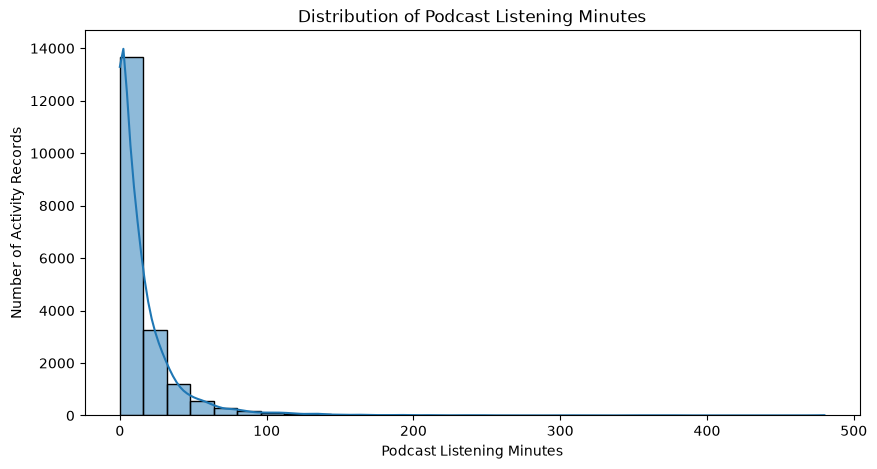

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df1,
    x='Podcast_Minutes_Listened',
    bins=30,
    kde=True
)

plt.title('Distribution of Podcast Listening Minutes')
plt.xlabel('Podcast Listening Minutes')
plt.ylabel('Number of Activity Records')

plt.show()

### Visualize Podcast Listening Distribution - Key Findings

1. The distribution of podcast listening minutes is strongly right-skewed. Most activity records show relatively low podcast listening time, while a small number of records have substantially higher listening durations.

2. The mean listening time (15.63 minutes) is higher than the median (7.60 minutes), supporting the presence of positive skewness.

3. This distribution suggests that high-listening observations may influence the average. Therefore, the primary analysis will use Welch's t-test, with bootstrap confidence intervals and a Mann–Whitney test as robustness checks.

Note: This visualization represents activity records rather than independent randomized users. The final experiment analysis will aggregate listening time at the user level.

## SRM (Sample Ratio Mismatch) test

In [10]:
from scipy.stats import chisquare

# Actual number of users in each group
observed = df2['Variant'].value_counts().reindex(
    ['Control', 'Treatment']
).values

# Expected number of users in each group (50/50)
expected = [1000, 1000]

# Perform Chi-square goodness-of-fit test
chi_stat, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print("Observed counts:", observed)
print("Expected counts:", expected)
print("Chi-square statistic:", chi_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("SRM detected: Group allocation differs significantly from 50/50.")
else:
    print("No significant SRM detected.")

Observed counts: [1015  985]
Expected counts: [1000, 1000]
Chi-square statistic: 0.45
P-value: 0.502334954360502
No significant SRM detected.


### SRM Test – Results and Interpretation.

Record:
- Expected allocation: 50% Control / 50% Treatment.
- Actual allocation: 50.75% Control / 49.25% Treatment.
- Chi-square statistic: 0.45.
- P-value: 0.5023.
- Conclusion: No significant SRM detected. The experiment passes the sample ratio mismatch check.

## Group balance checks

### Region distribution by experiment group

In [11]:
from scipy.stats import chi2_contingency

# Create a contingency table
region_table = pd.crosstab(
    df2['Variant'],
    df2['Region']
)

print("Region distribution by experiment group:")
display(region_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(region_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Region distribution by experiment group:


Region,apac,europe,latam,mea,north america
Variant,,,,,
Control,155,307,173,55,325
Treatment,189,291,130,67,308


Chi-square statistic: 11.080245999137887
P-value: 0.025676810052820173


### Region Distribution by experiment group
A Chi-square test of independence was conducted to examine whether Region distribution differed between the Control and Treatment groups.

The test produced a Chi-square statistic of 11.08 and a p-value of 0.0257.

At the 5% significance level, the result indicates a statistically significant difference in regional distribution between the two experiment groups.

The largest observed differences were in APAC and LATAM representation.

This imbalance does not automatically invalidate the experiment. However, Region will be considered as a covariate in the final adjusted analysis to account for potential regional differences in podcast listening behaviour.

### Premium Status balance test

In [12]:
from scipy.stats import chi2_contingency

# Create a contingency table
premium_table = pd.crosstab(
    df2['Variant'],
    df2['Premium_Status']
)

print("Premium Status distribution by group:")
display(premium_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(premium_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Premium Status distribution by group:


Premium_Status,Free,Premium
Variant,,
Control,560,455
Treatment,541,444


Chi-square statistic: 0.004456907487862746
P-value: 0.9467727087522845


### Premium Status distribution by group- Key findings
A Chi-square test of independence was conducted to examine whether Premium Status distribution differed between the Control and Treatment groups.

The test produced a Chi-square statistic of 0.0045 and a p-value of 0.9468.

Since the p-value is greater than the 0.05 significance level, there is no statistically significant evidence of an imbalance in Premium Status between the two groups.

The distribution of Free and Premium users is nearly identical across both experiment groups.

### Account Age balance test

In [13]:
from scipy.stats import ttest_ind

# Separate account age by experiment group
control_age = df2.loc[
    df2['Variant'] == 'Control',
    'Account_Age_Days'
].dropna()

treatment_age = df2.loc[
    df2['Variant'] == 'Treatment',
    'Account_Age_Days'
].dropna()

# Compare group averages
print("Control mean:", control_age.mean())
print("Treatment mean:", treatment_age.mean())

print("Control count:", len(control_age))
print("Treatment count:", len(treatment_age))

# Welch's t-test
t_stat, p_value = ttest_ind(
    control_age,
    treatment_age,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

Control mean: 845.3149448345035
Treatment mean: 807.3884892086331
Control count: 997
Treatment count: 973
T-statistic: 1.4839528111743836
P-value: 0.13798190402273205


### Account Age balance test-Key Findings
Welch's independent two-sample t-test was conducted to compare Account Age between the Control and Treatment groups.

The Control group had an average account age of 845.31 days (997 observations), while the Treatment group had an average of 807.39 days (973 observations).

The test produced a t-statistic of 1.4840 and a p-value of 0.1380.

Since the p-value is greater than the 0.05 significance level, there is no statistically significant evidence of an Account Age difference between the two groups.

The 30 missing Account Age values were excluded from this comparison.

## Primary Metric Analysis

In [14]:
# Attach experiment group to activity records
activity_check = df1.merge(
    df2[['User_ID', 'Variant']],
    on='User_ID',
    how='inner'
)

# Count missing and non-missing podcast values by group
missing_summary = pd.crosstab(
    activity_check['Variant'],
    activity_check['Podcast_Minutes_Listened'].isna()
)

missing_summary.columns = ['Available', 'Missing']

print("Podcast listening data completeness by group:")
display(missing_summary)

# Calculate missing percentage
missing_percentage = (
    activity_check.groupby('Variant')['Podcast_Minutes_Listened']
    .apply(lambda x: x.isna().mean() * 100)
)

print("\nMissing percentage by group:")
display(missing_percentage)

Podcast listening data completeness by group:


,Available,Missing
Variant,,
Control,9785,101
Treatment,9689,68



Missing percentage by group:


Variant
Control      1.021647
Treatment    0.696936
Name: Podcast_Minutes_Listened, dtype: float64

In [15]:
# Examine missing-value reasons by experiment group

missing_reasons = activity_check[
    activity_check['Podcast_Minutes_Listened'].isna()
]

reason_summary = pd.crosstab(
    missing_reasons['Variant'],
    missing_reasons['Missing_Reason']
)

print("Missing podcast listening values by reason:")
display(reason_summary)

Missing podcast listening values by reason:


Missing_Reason,Impossible Value,Originally Missing
Variant,,
Control,10,91
Treatment,2,66


### Missing podcast listening data
The investigation identified 169 missing podcast listening values among activity records belonging to matched experiment users.

Of these, 12 were caused by impossible listening measurements exceeding 1,440 minutes (10 Control and 2 Treatment). These values were converted to missing during data cleaning.

The remaining 157 values were originally missing (91 Control and 66 Treatment).

The reason for the originally missing values could not yet be established. Therefore, missing values will not automatically be replaced with zero, as doing so could introduce bias into the primary metric.

The analysis will preserve the randomized user population and document the missing-data limitation.

In [16]:
# Count missing podcast values for each date
daily_missing = (
    activity_check
    .groupby(['Date', 'Variant'])['Podcast_Minutes_Listened']
    .apply(lambda x: x.isna().sum())
    .unstack(fill_value=0)
)

print("Missing podcast values by date:")
display(daily_missing)

Missing podcast values by date:


Variant,Control,Treatment
Date,,
2025-03-03,8,11
2025-03-04,4,3
2025-03-05,6,5
2025-03-06,9,7
2025-03-07,7,9
2025-03-08,10,2
2025-03-09,9,1
2025-03-10,5,3
2025-03-11,8,4


In [17]:
# Count activity records for each user
user_activity_days = (
    activity_check
    .groupby(['User_ID', 'Variant'])['Date']
    .nunique()
    .reset_index(name='Active_Days')
)

print("Activity-day coverage by experiment group:")

display(
    user_activity_days
    .groupby('Variant')['Active_Days']
    .describe()
    .round(2)
)

Activity-day coverage by experiment group:


,count,mean,std,min,25%,50%,75%,max
Variant,,,,,,,,
Control,1015.0,9.74,2.54,1.0,8.0,10.0,12.0,14.0
Treatment,985.0,9.91,2.63,1.0,8.0,10.0,12.0,14.0


In [18]:
from scipy.stats import ttest_ind

control_days = user_activity_days.loc[
    user_activity_days['Variant'] == 'Control',
    'Active_Days'
]

treatment_days = user_activity_days.loc[
    user_activity_days['Variant'] == 'Treatment',
    'Active_Days'
]

t_stat, p_value = ttest_ind(
    control_days,
    treatment_days,
    equal_var=False
)

print("Control mean:", control_days.mean())
print("Treatment mean:", treatment_days.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Control mean: 9.739901477832513
Treatment mean: 9.905583756345179
T-statistic: -1.431840842363342
P-value: 0.15234641900548626


### Build the user-level ITT dataset

In [19]:
# Count missing podcast records for each user
user_missing = (
    activity_check
    .groupby(['User_ID', 'Variant'])
    .agg(
        Total_Activity_Days=('Date', 'nunique'),
        Missing_Podcast_Records=(
            'Podcast_Minutes_Listened',
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# Count users with at least one missing podcast value
users_with_missing = user_missing[
    user_missing['Missing_Podcast_Records'] > 0
]

print("Users with at least one missing podcast value:")
print(users_with_missing.groupby('Variant')['User_ID'].nunique())

print("\nTotal affected users:")
print(users_with_missing['User_ID'].nunique())

Users with at least one missing podcast value:
Variant
Control      97
Treatment    66
Name: User_ID, dtype: int64

Total affected users:
163


In [20]:
from scipy.stats import chi2_contingency

# Create a table of users with and without missing values
missing_user_table = pd.crosstab(
    user_missing['Variant'],
    user_missing['Missing_Podcast_Records'] > 0
)

missing_user_table.columns = ['No Missing', 'Has Missing']

print(missing_user_table)

# Chi-square test
chi_stat, p_value, dof, expected = chi2_contingency(
    missing_user_table
)

print("\nChi-square statistic:", chi_stat)
print("P-value:", p_value)

           No Missing  Has Missing
Variant                           
Control           918           97
Treatment         919           66

Chi-square statistic: 5.072613730727455
P-value: 0.024306706914555675


### Missing Outcome Data:
 A chi-square test identified a statistically significant difference in the proportion of users with at least one missing podcast listening measurement between Control (9.56%) and Treatment (6.70%), χ² = 5.073, p = 0.0243. This indicates differential outcome-data availability across experiment groups. The finding will be considered when constructing the primary ITT dataset and interpreting the treatment effect.

In [21]:
# Merge premium status with activity data
premium_missing_check = activity_check.merge(
    df2[['User_ID', 'Premium_Status']],
    on='User_ID',
    how='left'
)

# Count missing podcast measurements by experiment group and premium status
premium_missing_summary = pd.crosstab(
    [premium_missing_check['Variant'],
     premium_missing_check['Premium_Status']],
    premium_missing_check['Podcast_Minutes_Listened'].isna()
)

premium_missing_summary.columns = ['Available', 'Missing']

print(premium_missing_summary)

                          Available  Missing
Variant   Premium_Status                    
Control   Free                 5363       66
          Premium              4422       35
Treatment Free                 5355       33
          Premium              4334       35


### Test missingness across all four groups

In [22]:
from scipy.stats import chi2_contingency

premium_missing_table = pd.crosstab(
    [premium_missing_check['Variant'],
     premium_missing_check['Premium_Status']],
    premium_missing_check['Podcast_Minutes_Listened'].isna()
)

chi_stat, p_value, dof, expected = chi2_contingency(
    premium_missing_table
)

print("Chi-square statistic:", chi_stat)
print("P-value:", p_value)

Chi-square statistic: 12.392518034392964
P-value: 0.0061526740247024175


### Missing Podcast Listening Data by Experiment Group and Premium Status
**Objective:**  
To investigate whether missing values in `Podcast_Minutes_Listened` are distributed differently across the Control and Treatment groups and their subscription categories (Free and Premium).

**Method:**  
A Chi-square test of independence was performed to examine the relationship between experiment group, Premium Status, and missing podcast-listening records.

**Results:**

| Experiment Group | Premium Status | Available Records | Missing Records | Missing Rate |
|---|---|---:|---:|---:|
| Control | Free | 5,363 | 66 | 1.22% |
| Control | Premium | 4,422 | 35 | 0.79% |
| Treatment | Free | 5,355 | 33 | 0.61% |
| Treatment | Premium | 4,334 | 35 | 0.80% |

**Statistical Test Results:**
- Chi-square statistic: 12.39
- P-value: 0.00615
- Significance level: 0.05

**Interpretation:**  
The p-value is below 0.05, indicating a statistically significant association between the four experiment-group/subscription combinations and the presence of missing podcast-listening records.

The Control-Free group has the highest missing-record rate (1.22%), while the Treatment-Free group has the lowest (0.61%). Missingness therefore does not appear to be evenly distributed across these four groups.

**Potential Impact:**  
Unequal missingness may affect the reliability of the primary metric, Average Daily Podcast Listening Minutes per Randomized User. If missing values are related to actual listening behavior, the estimated treatment effect could be biased.

**Action Taken / Recommended:**
1. Retain missing values as NaN rather than automatically replacing them with zero.
2. Investigate the cause of missing records.
3. Preserve all randomized users in the experiment dataset.
4. Conduct sensitivity analysis when calculating the primary metric.
5. Document missing-data limitations in the final executive summary.

**Conclusion:**  
A statistically significant difference in missing-record patterns was detected across experiment and subscription groups. This is a data-quality concern that should be considered when interpreting the experiment results.

In [23]:
# Importing the analysis in cleaning log csv
import pandas as pd

cleaning_log = pd.read_csv(r"C:\Spotify_A-B_Test_project\01_Data\02_processed_data\cleaning_log.csv")

new_entry = {
    "Dataset": "User Activity",
    "Issue": "Missing podcast records differ across experiment and subscription groups",
    "Records_Affected": 169,
    "Action_Taken": "Performed Chi-square test; retained missing values as NaN",
    "Reason": "Significant difference detected (chi-square = 12.39, p = 0.00615). Control-Free had the highest missing rate (1.22%). Sensitivity analysis required."
}

cleaning_log.loc[len(cleaning_log)] = new_entry

print(cleaning_log.tail())

cleaning_log.to_csv("cleaning_log.csv", index=False)

print("Cleaning log updated successfully!")

check_log = pd.read_csv("cleaning_log.csv")

print(check_log.tail(3))
print("Total rows:", len(check_log))

               Dataset                                              Issue  \
5  User Experiment Map                     Inconsistent Region formatting   
6  Daily User Activity                                     Date data type   
7  Daily User Activity  Missing podcast records differ across experime...   
8        User Activity  Missing podcast records differ across experime...   
9        User Activity  Missing podcast records differ across experime...   

  Records_Affected                                       Action_Taken  \
5             2000  Converted region names to lowercase and remove...   
6        Validated                         Converted Date to datetime   
7              169  Performed Chi-square test; retained missing va...   
8              169  Performed Chi-square test; retained missing va...   
9              169  Performed Chi-square test; retained missing va...   

                                              Reason  
5                Ensure consistent region c

Cleaning log updated successfully!
               Dataset                                              Issue  \
7  Daily User Activity  Missing podcast records differ across experime...   
8        User Activity  Missing podcast records differ across experime...   
9        User Activity  Missing podcast records differ across experime...   

  Records_Affected                                       Action_Taken  \
7              169  Performed Chi-square test; retained missing va...   
8              169  Performed Chi-square test; retained missing va...   
9              169  Performed Chi-square test; retained missing va...   

                                              Reason  
7  Significant difference detected (chi-square = ...  
8  Significant difference detected (chi-square = ...  
9  Significant difference detected (chi-square = ...  
Total rows: 10


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13776\1848389406.py:14: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype str cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  cleaning_log.loc[len(cleaning_log)] = new_entry


In [24]:
# Create user-level analysis dataset

user_analysis = df2.copy()

# Aggregate podcast listening activity by user
podcast_summary = (
    df1
    .groupby('User_ID')
    .agg(
        Total_Podcast_Minutes=(
            'Podcast_Minutes_Listened', 'sum'
        ),
        Recorded_Activity_Days=('Date', 'nunique'),
        Missing_Podcast_Records=(
            'Podcast_Minutes_Listened',
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# Merge activity summary with randomized users
user_analysis = user_analysis.merge(
    podcast_summary,
    on='User_ID',
    how='left'
)

# Check dataset
print("Total users:", len(user_analysis))
print("Unique users:", user_analysis['User_ID'].nunique())

display(user_analysis.head())

Total users: 2000
Unique users: 2000


,User_ID,Variant,Region,Premium_Status,Account_Age_Days,Total_Podcast_Minutes,Recorded_Activity_Days,Missing_Podcast_Records
0,U428241,Treatment,latam,Free,236.0,178.5,12,0
1,U454990,Control,europe,Free,770.0,89.1,8,0
2,U195228,Treatment,apac,Premium,983.0,59.0,13,0
3,U651302,Treatment,north america,Free,314.0,139.6,11,0
4,U926541,Control,europe,Free,430.0,57.7,9,0


In [25]:
# Calculate valid podcast measurement days for each user

valid_days = (
    df1
    .groupby('User_ID')['Podcast_Minutes_Listened']
    .count()
    .reset_index(name='Valid_Podcast_Days')
)

# Add valid measurement days to user-level dataset
user_analysis = user_analysis.merge(
    valid_days,
    on='User_ID',
    how='left'
)

# Identify users with missing podcast measurements
user_analysis['Valid_Podcast_Days'] = (
    user_analysis['Valid_Podcast_Days'].fillna(0)
)

user_analysis['Incomplete_Measurements'] = (
    user_analysis['Missing_Podcast_Records'] > 0
)

# Display coverage summary
print("Measurement coverage by experiment group:")

display(
    user_analysis.groupby('Variant').agg(
        Total_Users=('User_ID', 'count'),
        Average_Valid_Days=('Valid_Podcast_Days', 'mean'),
        Users_With_Missing=(
            'Incomplete_Measurements', 'sum'
        )
    )
)

Measurement coverage by experiment group:


,Total_Users,Average_Valid_Days,Users_With_Missing
Variant,,,
Control,1015,9.640394,97
Treatment,985,9.836548,66


In [26]:
# Calculate observed average daily podcast listening minutes

user_analysis['Observed_Avg_Daily_Podcast_Minutes'] = (
    user_analysis['Total_Podcast_Minutes'] / 14
)

# Display results by experiment group
primary_summary = (
    user_analysis
    .groupby('Variant')
    .agg(
        Users=('User_ID', 'count'),
        Average_Daily_Minutes=(
            'Observed_Avg_Daily_Podcast_Minutes', 'mean'
        ),
        Median_Daily_Minutes=(
            'Observed_Avg_Daily_Podcast_Minutes', 'median'
        ),
        Std_Deviation=(
            'Observed_Avg_Daily_Podcast_Minutes', 'std'
        )
    )
)

display(primary_summary)

,Users,Average_Daily_Minutes,Median_Daily_Minutes,Std_Deviation
Variant,,,,
Control,1015,10.348311,7.828571,8.929907
Treatment,985,11.423778,8.300000,10.696754


In [27]:
control_mean = primary_summary.loc[
    'Control', 'Average_Daily_Minutes'
]

treatment_mean = primary_summary.loc[
    'Treatment', 'Average_Daily_Minutes'
]

absolute_effect = treatment_mean - control_mean

percentage_effect = (
    absolute_effect / control_mean
) * 100

print("Control average:", round(control_mean, 3))
print("Treatment average:", round(treatment_mean, 3))
print("Absolute treatment effect:", round(absolute_effect, 3))
print("Percentage improvement:", round(percentage_effect, 2), "%")

Control average: 10.348
Treatment average: 11.424
Absolute treatment effect: 1.075
Percentage improvement: 10.39 %


In [28]:
from scipy.stats import ttest_ind

control_data = user_analysis.loc[
    user_analysis['Variant'] == 'Control',
    'Observed_Avg_Daily_Podcast_Minutes'
]

treatment_data = user_analysis.loc[
    user_analysis['Variant'] == 'Treatment',
    'Observed_Avg_Daily_Podcast_Minutes'
]

t_stat, p_value = ttest_ind(
    treatment_data,
    control_data,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 2.4371550931097916
P-value: 0.014893819488781216


In [29]:
from scipy.stats import t

# Group statistics
n_control = len(control_data)
n_treatment = len(treatment_data)

mean_control = control_data.mean()
mean_treatment = treatment_data.mean()

std_control = control_data.std()
std_treatment = treatment_data.std()

# Difference in means
effect = mean_treatment - mean_control

# Standard error (Welch)
se = np.sqrt(
    (std_control**2 / n_control) +
    (std_treatment**2 / n_treatment)
)

# Welch-Satterthwaite degrees of freedom
df_welch = (
    (std_control**2 / n_control +
     std_treatment**2 / n_treatment)**2
    /
    (
        (std_control**2 / n_control)**2 / (n_control - 1)
        +
        (std_treatment**2 / n_treatment)**2 / (n_treatment - 1)
    )
)

# 95% confidence interval
critical_value = t.ppf(0.975, df_welch)

ci_lower = effect - critical_value * se
ci_upper = effect + critical_value * se

print("Treatment effect:", round(effect, 4))
print("95% CI:", round(ci_lower, 4), "to", round(ci_upper, 4))
print("Degrees of freedom:", round(df_welch, 2))

Treatment effect: 1.0755
95% CI: 0.21 to 1.9409
Degrees of freedom: 1915.05


## Primary metric- Key Findings
**Primary Metric:** Average Daily Podcast Listening Minutes per Randomized User.

**Objective:** Determine whether the Video-First Discovery Feed increases daily podcast listening compared with the existing static cover-art feed.

**Results:**
- Control average: 10.3483 minutes/day.
- Treatment average: 11.4238 minutes/day.
- Absolute treatment effect: +1.0755 minutes/day.
- Relative improvement: +10.39%.
- T-statistic: 2.4372.
- P-value: 0.01489.
- 95% confidence interval: [0.2100, 1.9409].

**Interpretation:**

The Treatment group showed approximately 10.39% higher observed average daily podcast listening than the Control group. The difference was statistically significant at the 5% significance level.

The confidence interval suggests an observed increase of approximately 0.21 to 1.94 podcast minutes per day.

**Limitation:**

Podcast listening measurements are missing for some users, with a higher proportion of affected users in the Control group. Therefore, this result is preliminary and requires sensitivity analysis before making a final experiment recommendation.

**Preliminary Conclusion:**

The Video-First Discovery Feed shows promising positive results for podcast listening engagement. Further robustness checks and guardrail analysis are required before recommending launch.

## Robustness Check – Mann–Whitney U Test

In [30]:
from scipy.stats import mannwhitneyu

u_stat, mw_p_value = mannwhitneyu(
    treatment_data,
    control_data,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", u_stat)
print("Mann-Whitney p-value:", mw_p_value)

Mann-Whitney U statistic: 524384.0
Mann-Whitney p-value: 0.057802621991277676


##  Robustness Check – Mann–Whitney U Test- Key Findings
**Purpose:** Check whether the primary metric result is supported by a non-parametric statistical test.

**Results:**
- Mann–Whitney U statistic: 524,384.
- P-value: 0.05780.
- Significance threshold: 0.05.

**Interpretation:**

The Mann–Whitney U test did not identify a statistically significant difference between the Treatment and Control distributions at the 5% significance level.

This contrasts with the Welch's t-test, which found a statistically significant positive difference in observed average daily listening time.

**Conclusion:**

The primary result is not fully robust across the two statistical tests. The observed mean difference is positive, but the non-parametric test does not confirm a statistically significant distributional difference.

The result should therefore be interpreted cautiously, particularly because podcast listening measurements have unequal missingness across experiment groups.

## Bootstrap Robustus Check

In [31]:
import numpy as np

# Reproducible results
np.random.seed(42)

# Number of bootstrap samples
n_bootstrap = 5000

bootstrap_effects = []

for i in range(n_bootstrap):

    # Resample each group independently
    control_sample = np.random.choice(
        control_data,
        size=len(control_data),
        replace=True
    )

    treatment_sample = np.random.choice(
        treatment_data,
        size=len(treatment_data),
        replace=True
    )

    # Calculate difference in means
    effect = treatment_sample.mean() - control_sample.mean()

    bootstrap_effects.append(effect)

# Calculate 95% confidence interval
ci_lower = np.percentile(bootstrap_effects, 2.5)
ci_upper = np.percentile(bootstrap_effects, 97.5)

print("Bootstrap treatment effect:", round(np.mean(bootstrap_effects), 4))
print("Bootstrap 95% CI:", round(ci_lower, 4), "to", round(ci_upper, 4))

Bootstrap treatment effect: 1.0848
Bootstrap 95% CI: 0.2212 to 1.9857


## Bootstrap Robustus Check- Key Findings
**Method:** Non-parametric bootstrap with 5,000 independent resamples from the Treatment and Control user-level datasets.

**Results:**
- Bootstrap treatment effect: +1.0848 minutes/day.
- Bootstrap 95% confidence interval: [0.2212, 1.9857].

**Interpretation:**

The bootstrap confidence interval is entirely above zero, supporting a positive difference in observed average daily podcast listening between the Treatment and Control groups.

The bootstrap estimate is consistent with the Welch's t-test estimate.

**Limitation:**

The bootstrap does not correct for missing podcast measurements or unequal missingness between experiment groups. Therefore, these findings remain preliminary.

## Missing Data Sensitivity

In [32]:
missing_summary = (
    user_analysis.groupby('Variant')
    .agg(
        Total_Users=('User_ID', 'count'),
        Users_With_Missing=('Incomplete_Measurements', 'sum'),
        Average_Valid_Days=('Valid_Podcast_Days', 'mean')
    )
)

missing_summary['Missing_User_Percentage'] = (
    missing_summary['Users_With_Missing']
    / missing_summary['Total_Users'] * 100
)

print(missing_summary.round(2))

           Total_Users  Users_With_Missing  Average_Valid_Days  \
Variant                                                          
Control           1015                  97                9.64   
Treatment          985                  66                9.84   

           Missing_User_Percentage  
Variant                             
Control                       9.56  
Treatment                     6.70  


In [33]:
# Scenario A: Assume missing measurements = 0
user_analysis['Scenario_Zero'] = (
    user_analysis['Total_Podcast_Minutes'] / 14
)

# Scenario B: Assume missing measurements = 480
user_analysis['Scenario_Max'] = (
    (
        user_analysis['Total_Podcast_Minutes']
        + user_analysis['Missing_Podcast_Records'] * 480
    ) / 14
)

# Compare treatment and control
sensitivity_results = (
    user_analysis.groupby('Variant')
    .agg(
        Zero_Assumption=('Scenario_Zero', 'mean'),
        Maximum_Assumption=('Scenario_Max', 'mean')
    )
)

print(sensitivity_results.round(4))

# Calculate treatment effects
effect_zero = (
    sensitivity_results.loc['Treatment', 'Zero_Assumption']
    - sensitivity_results.loc['Control', 'Zero_Assumption']
)

effect_max = (
    sensitivity_results.loc['Treatment', 'Maximum_Assumption']
    - sensitivity_results.loc['Control', 'Maximum_Assumption']
)

print("\nTreatment effect under zero assumption:", round(effect_zero, 4))
print("Treatment effect under maximum assumption:", round(effect_max, 4))

           Zero_Assumption  Maximum_Assumption
Variant                                       
Control            10.3483             13.7600
Treatment          11.4238             13.7907

Treatment effect under zero assumption: 1.0755
Treatment effect under maximum assumption: 0.0307


## Missing Value sensitivity- Key Findings
**Objective:** Evaluate how assumptions about missing podcast listening measurements influence the estimated treatment effect.

**Scenario A – Missing measurements assumed to be zero:**
- Control: 10.3483 minutes/day.
- Treatment: 11.4238 minutes/day.
- Treatment effect: +1.0755 minutes/day.

**Scenario B – Missing measurements assumed to be 480 minutes:**
- Control: 13.7600 minutes/day.
- Treatment: 13.7907 minutes/day.
- Treatment effect: +0.0307 minutes/day.

**Interpretation:**

The estimated treatment effect changes substantially under different missing-data assumptions. Under the zero-minute assumption, Treatment shows a positive difference of approximately 1.08 minutes per day. Under the extreme 480-minute assumption, the difference nearly disappears.

This indicates that the primary metric result is sensitive to missing-data assumptions.

**Conclusion:**

The positive observed treatment effect should be interpreted cautiously. The actual meaning of missing podcast measurements must be established before drawing a definitive causal conclusion.

The 480-minute scenario is an extreme sensitivity bound, not an estimate of actual missing listening time.

In [34]:
print("Total activity records:", len(df1))

print(
    "Unique user-date combinations:",
    df1[['User_ID', 'Date']].drop_duplicates().shape[0]
)

print(
    "Duplicate user-date combinations:",
    df1.duplicated(
        subset=['User_ID', 'Date']
    ).sum()
)

print(
    "Total randomized users:",
    df2['User_ID'].nunique()
)

Total activity records: 19663
Unique user-date combinations: 19663
Duplicate user-date combinations: 0
Total randomized users: 2000


## Activity coverage per user

In [35]:
activity_coverage = (
    user_analysis.groupby('Variant')
    .agg(
        Total_Users=('User_ID', 'count'),
        Users_With_14_Days=(
            'Recorded_Activity_Days',
            lambda x: (x == 14).sum()
        ),
        Users_With_Fewer_Than_14_Days=(
            'Recorded_Activity_Days',
            lambda x: (x < 14).sum()
        ),
        Average_Recorded_Days=(
            'Recorded_Activity_Days',
            'mean'
        )
    )
)

activity_coverage['Percentage_Fewer_Than_14_Days'] = (
    activity_coverage['Users_With_Fewer_Than_14_Days']
    / activity_coverage['Total_Users'] * 100
)

print(activity_coverage.round(2))

           Total_Users  Users_With_14_Days  Users_With_Fewer_Than_14_Days  \
Variant                                                                     
Control           1015                  58                            957   
Treatment          985                  58                            927   

           Average_Recorded_Days  Percentage_Fewer_Than_14_Days  
Variant                                                          
Control                     9.74                          94.29  
Treatment                   9.91                          94.11  


## Activity coverage analysis- Key Findings
**Objective:** Evaluate activity-day coverage across the randomized experiment groups.

**Results:**
- Control users with 14 recorded days: 58 (5.71%).
- Treatment users with 14 recorded days: 58 (5.89%).
- Control average recorded days: 9.74.
- Treatment average recorded days: 9.91.
- Approximately 94% of users in both groups have fewer than 14 recorded activity days.

**Interpretation:**

Activity-day coverage is similar between the Treatment and Control groups. However, most users do not have a complete 14-day activity record.

This creates uncertainty about whether absent activity records represent zero listening or unobserved data.

**Conclusion:**

The primary metric currently represents partial observed listening divided by 14, rather than a fully verified 14-day listening outcome. Further investigation of the activity logging process is necessary.

## Check the Number of Missing Days

In [36]:
coverage_distribution = (
    user_analysis
    .groupby(['Variant', 'Recorded_Activity_Days'])
    .size()
    .reset_index(name='Number_of_Users')
)

print(
    coverage_distribution.pivot(
        index='Recorded_Activity_Days',
        columns='Variant',
        values='Number_of_Users'
    ).fillna(0).astype(int)
)

Variant                 Control  Treatment
Recorded_Activity_Days                    
1                             2          1
2                             4          3
3                             5         13
4                            16         14
5                            31         34
6                            55         54
7                            90         63
8                           104         92
9                           127        117
10                          165        139
11                          136        146
12                          137        140
13                           85        111
14                           58         58


## Activity days missing
**Issue:** Incomplete daily activity records.

**Finding:** The experiment contains 19,663 activity records compared with 28,000 possible user-day combinations across 2,000 users and 14 days.

Approximately 94% of users have fewer than 14 recorded activity days.

**Investigation:** Dataset documentation does not explain why some user-day records are absent.

**Action Taken:** Retained the available records without automatically imputing absent activity days as zero.

**Reason:** Treating absent records as zero without confirmation could introduce measurement error and bias the primary metric.

**Recommendation:** Request clarification from the data engineering team regarding activity logging and inactive-day behavior.

## Final Visualisation

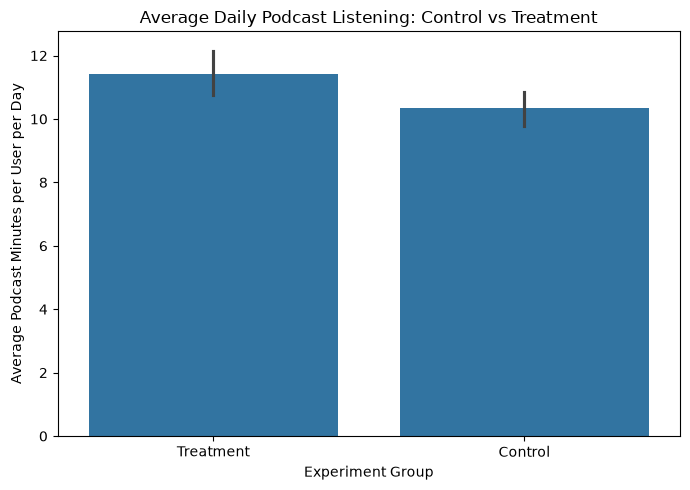

In [37]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=user_analysis,
    x='Variant',
    y='Observed_Avg_Daily_Podcast_Minutes',
    errorbar=('ci', 95)
)

plt.title('Average Daily Podcast Listening: Control vs Treatment')
plt.xlabel('Experiment Group')
plt.ylabel('Average Podcast Minutes per User per Day')

plt.tight_layout()
plt.show()